# Trajectory RMSE distributions

This notebook visualizes trajectory RMSE distributions for independently
initialized paths. For every ordered pair $i\ne j$, it compares real trajectory
$X_i$ with real trajectory $X_j$ and with Gaussian, isotropic, chord, and
Brownian references constructed from initialization $j$. Each path is translated
to the origin and aligned with one trajectory-wide orthogonal Procrustes
transformation in VE coordinates.

The expensive all-pairs errors are computed offline. This notebook only loads the
saved artifact and draws the density and empirical CDF panels used in the paper.
Change `DATASET` in the configuration cell to inspect another dataset.


In [1]:
from pathlib import Path
import sys

import torch
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
SRC_ROOT = PROJECT_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from universal.analysis import load_independent_start_result


METHODS = (
    'real',
    'gaussian',
    'isotropic_gaussian',
    'gaussian_chord',
    'brownian_bridge',
)
LABELS = {
    'real': 'Real trajectory',
    'gaussian': 'Empirical Gaussian',
    'isotropic_gaussian': 'Isotropic Gaussian',
    'gaussian_chord': 'Gaussian chord',
    'brownian_bridge': 'Brownian bridge',
}
# Consistent publication palette used by every plot in this notebook.
COLORS = {
    'real': '#D94B32',             # vermilion
    'gaussian': '#0066FF',         # bright blue
    'isotropic_gaussian': '#8B008B',  # deep magenta
    'gaussian_chord': '#008F5A',   # deep emerald green
    'brownian_bridge': '#555555',  # charcoal null baseline
}
PLOT_ZORDER = {
    'brownian_bridge': 1,
    'gaussian_chord': 2,
    'isotropic_gaussian': 3,
    'real': 4,
    'gaussian': 5,
}

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11, 'mathtext.fontset': 'cm'})


In [2]:
# Select one completed trajectory run.
DATASET = 'cifar10'  # 'cifar10', 'diffwave', 'diffusion_lm', or 'pvd'
RUN_NAMES = {
    'cifar10': 'euler_karras_201_seed0_199',
    'diffwave': 'native_ddim_ve_201_sample0_199',
    'diffusion_lm': 'ddim200_seed0_199',
    'pvd': 'chair_ddim_201_raw_seed0_199',
}
run_dir = PROJECT_ROOT / 'runs' / DATASET / 'trajectories' / RUN_NAMES[DATASET]
result_path = (
    run_dir / 'analyses' / 'independent_start_rmse' / 'pairwise_errors.pt'
)
artifact = load_independent_start_result(result_path)
errors = artifact['errors']
completed = artifact['completed_targets']
provenance = artifact['provenance']

print('Independent-start result')
print(f'  Dataset:           {DATASET}')
print(f'  Loaded artifact:   {result_path.relative_to(PROJECT_ROOT)}')
print(f'  Completed targets: {int(completed.sum())}/{len(completed)}')
print(f"  Coordinate space:  {provenance['space'].upper()}")
print(f"  States:            {provenance['num_states']}")
print(f"  Dimension:         {provenance['dimension']}")
print(f"  Alignment:         {provenance['alignment']}")
print(f"  Brownian rule:     {provenance['brownian_amplitude']}")


Independent-start result
  Dataset:           cifar10
  Loaded artifact:   runs/cifar10/trajectories/euler_karras_201_seed0_199/analyses/independent_start_rmse/pairwise_errors.pt
  Completed targets: 200/200
  Coordinate space:  VE
  States:            201
  Dimension:         3072
  Alignment:         start_centered_orthogonal_procrustes_reflection_allowed
  Brownian rule:     matched_to_X_j_minus_Gaussian_chord_j


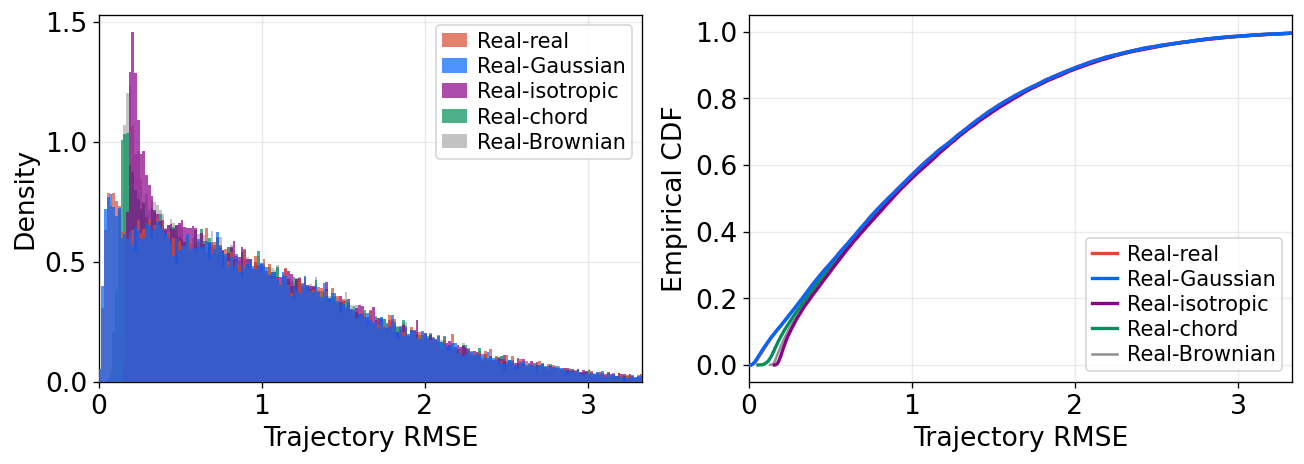

In [3]:
# Pairwise errors compare each completed real target i with candidates j != i.
pairwise_methods = (
    'real',
    'gaussian',
    'isotropic_gaussian',
    'gaussian_chord',
    'brownian_bridge',
)
pairwise_labels = {
    'real': 'Real-real',
    'gaussian': 'Real-Gaussian',
    'isotropic_gaussian': 'Real-isotropic',
    'gaussian_chord': 'Real-chord',
    'brownian_bridge': 'Real-Brownian',
}
pairwise_errors = {}
for method in pairwise_methods:
    values = errors[method][completed].reshape(-1)
    pairwise_errors[method] = values[torch.isfinite(values)]

# The shared range and bins make the density and ECDF directly comparable.
all_pairwise_errors = torch.cat(list(pairwise_errors.values()))
display_max = float(torch.quantile(all_pairwise_errors, .995))
histogram_bins = torch.linspace(0, display_max, 200)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fig.subplots_adjust(left=.08, bottom=.19, right=.98, top=.96, wspace=.28)
for method in pairwise_methods:
    values = pairwise_errors[method]
    _, _, patches = axes[0].hist(
        values.numpy(), bins=histogram_bins.numpy(), density=True,
        lw=1.5 if method == 'brownian_bridge' else 2,
        color=COLORS[method],
        alpha=.35 if method == 'brownian_bridge' else .7,
        zorder=PLOT_ZORDER[method],
        label=pairwise_labels[method],
    )
    for patch in patches:
        patch.set_rasterized(True)

    ordered = values.sort().values
    cumulative = torch.arange(1, len(ordered) + 1) / len(ordered)
    axes[1].plot(
        ordered, cumulative,
        lw=1.5 if method == 'brownian_bridge' else 2,
        alpha=.65 if method == 'brownian_bridge' else 1,
        color=COLORS[method], zorder=PLOT_ZORDER[method],
        label=pairwise_labels[method],
    )

for ax in axes:
    ax.set_xlim(0, display_max)
    ax.set_xlabel('Trajectory RMSE', fontsize=16)
    ax.tick_params(axis='both', labelsize=16)
    ax.grid(alpha=.25)
axes[0].set_ylabel('Density', fontsize=16)
axes[1].set_ylabel('Empirical CDF', fontsize=16)
for ax in axes:
    ax.legend(
        fontsize=12.5, frameon=True, handlelength=1.2,
        handletextpad=.45, labelspacing=.25, borderpad=.3,
    )
plt.tight_layout()
# fig.savefig(f'{DATASET}_pairwise_rmse.pdf', dpi=200)
plt.show()
